# Fine-tuning `wav2vec2-xlsr-53-espeak-cv-ft` on PLD Filipino (FIL)

This notebook fine-tunes [`facebook/wav2vec2-xlsr-53-espeak-cv-ft`](https://huggingface.co/facebook/wav2vec2-xlsr-53-espeak-cv-ft), a multilingual phoneme recogniser, on the Filipino/Tagalog part of the UP DSP Philippine Languages Database. It is meant to run on **Google Colab** with a T4, L4 or A100 GPU (an L4 is the best value).

**Data.** The labels are the broad IPA transcriptions built in `notebooks/EDA/PLD_FIL_EDA_G2P.ipynb`: Wiktionary pronunciations where available, otherwise Epitran plus correction rules, **without glottal stops**, and with personal and place names read the way the speakers read them (G2P notebook, sections 7.1 and 7.8). They are uploaded, together with the audio, as a private Hugging Face dataset by `scripts/data_loaders/PLD_FIL.py`, which also draws the train/validation/test split (section 2). Only the rows the G2P notebook recommends for training are included (readable, non-empty audio, no unreviewed numbers or symbols). Spontaneous speech is not part of the data, because it has no proper label yet.

**Contents**
1. Setup (packages, GPU, Hugging Face and Weights & Biases logins)
2. Data: splits, durations, label inventory
3. Vocabulary: a new output layer with the label phones, initialised from the pretrained one
4. Baseline: the pretrained model before fine-tuning
5. Training
6. Evaluation on held-out speakers
7. Saving the model

**Before running**
- In Colab: *Runtime → Change runtime type → L4 GPU* (or T4 / A100).
- Add your Hugging Face token as a Colab secret named `HF_TOKEN` (key icon in the left sidebar; give the notebook access). It needs **write** access, because checkpoints are pushed to a private model repo so that training can resume after Colab disconnects.
- Add your Weights & Biases API key (https://wandb.ai/authorize) as a Colab secret named `WANDB_API_KEY`. Training is tracked live on W&B (section 1).
- Set `HF_DATASET_ID`, `HF_USER` and `RUN_NAME` in the configuration cell below (checkpoints and the final model go to the private repo `HF_USER/RUN_NAME`).

**Running from the terminal with the Colab CLI** (instead of the browser):
```bash
colab new -s fil --gpu L4
colab exec -s fil -f PLD_FIL_wav2vec2_espeak_finetune.ipynb   # results are written to ..._output.ipynb
colab stop -s fil
```
With the CLI there are no Colab secrets, so set both keys first: `echo 'import os; os.environ["HF_TOKEN"]="hf_..."; os.environ["WANDB_API_KEY"]="..."' | colab exec -s fil`.

## 1. Setup

In [1]:
# Versions the notebook was tested with (Colab already provides torch and CUDA).
%pip install -q transformers==4.57.1 datasets==4.4.1 accelerate==1.12.0 soundfile==0.13.1 huggingface-hub==0.36.0 wandb==0.30.0 panphon==0.22.2

  Installing build dependencies ... done


  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.10.0 which is incompatible.


In [2]:
import io
import os
import re
import json
import math
import random
from collections import Counter

import numpy as np
import pandas as pd
import soundfile as sf
import torch
import matplotlib.pyplot as plt
import panphon
import panphon.distance
import wandb
from datasets import Audio, load_dataset, load_from_disk
from huggingface_hub import HfApi, snapshot_download
from transformers import (
    Trainer,
    TrainerCallback,
    TrainingArguments,
    Wav2Vec2CTCTokenizer,
    Wav2Vec2FeatureExtractor,
    Wav2Vec2ForCTC,
    Wav2Vec2Processor,
)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
if DEVICE == "cpu":
    print("WARNING: no GPU. Training on CPU is only usable with SMOKE_TEST = True.")

torch 2.11.0+cu130 | device: NVIDIA L4


### Configuration

All settings are in one place. The training defaults fit a **T4 (16 GB)** and also run on an L4 or A100: batches of 8 utterances with 4 accumulation steps (32 utterances per update), mixed precision (fp16 on a T4, bf16 on an L4/A100), gradient checkpointing, and training clips of at most 15 s.

`SMOKE_TEST = True` runs the whole notebook on a handful of utterances for two training steps. Use it to check the setup before spending GPU time.

In [3]:
HF_DATASET_ID = "jomszxcvb/PLD-FIL"  # dataset pushed by scripts/data_loaders/PLD_FIL.py (or a local save_to_disk folder)
HF_USER = "jomszxcvb"
BASE_MODEL_ID = "facebook/wav2vec2-xlsr-53-espeak-cv-ft"
OUTPUT_DIR = "/content/xlsr-53-espeak-pld-fil" if os.path.isdir("/content") else "xlsr-53-espeak-pld-fil"

SMOKE_TEST = False  # first run: tiny subset, 2 steps, nothing pushed. Set to False for real training
PUSH_TO_HUB = not SMOKE_TEST
SEED = 42

# Weights & Biases
WANDB_PROJECT = "pld-fil-xlsr-espeak"
WANDB_ENTITY = None  # W&B user or team; None = your default entity
RUN_NAME = "xlsr-53-espeak-pld-fil-03"  # W&B run id and model repo name: re-running with the same name resumes; change it for a new experiment

# training (T4 defaults)
MAX_TRAIN_SECONDS = 15.0  # longer clips are dropped from training only (memory)
BATCH_SIZE = 8
GRAD_ACCUM = 4
LEARNING_RATE = 1e-4
WARMUP_STEPS = 500
NUM_EPOCHS = 3
EVAL_SAVE_STEPS = 500
N_EVAL_DURING_TRAINING = 800  # validation utterances scored at every checkpoint
MASK_TIME_PROB = 0.05  # SpecAugment
MASK_FEATURE_PROB = 0.05
LAYERDROP = 0.05

if SMOKE_TEST:
    BATCH_SIZE, GRAD_ACCUM, EVAL_SAVE_STEPS, N_EVAL_DURING_TRAINING = 2, 1, 2, 4
    RUN_NAME = f"smoke-test-{pd.Timestamp.now():%Y%m%d-%H%M%S}"  # a new W&B run every time
HF_MODEL_ID = f"{HF_USER}/{RUN_NAME}"  # private model repo for this run's checkpoints and final model

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [4]:
# Hugging Face login: Colab secret HF_TOKEN, else the HF_TOKEN environment variable, else an interactive prompt.
token = os.environ.get("HF_TOKEN")
try:
    from google.colab import userdata

    token = token or userdata.get("HF_TOKEN")
except Exception:
    pass
if token:
    os.environ["HF_TOKEN"] = token
    print("logged in as", HfApi(token=token).whoami()["name"])
elif not os.path.isdir(HF_DATASET_ID):
    from huggingface_hub import notebook_login

    notebook_login()

logged in as jomszxcvb


In [5]:
# Weights & Biases login: Colab secret WANDB_API_KEY, else the WANDB_API_KEY environment variable, else an interactive prompt.
wandb_key = os.environ.get("WANDB_API_KEY")
try:
    from google.colab import userdata

    wandb_key = wandb_key or userdata.get("WANDB_API_KEY")
except Exception:
    pass
wandb.login(key=wandb_key) if wandb_key else wandb.login()

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.


wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.


wandb: No netrc file found, creating one.


wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


wandb: Currently logged in as: jomszxc (tiniglabs) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

### Experiment tracking (Weights & Biases)

Everything about the run is logged to one W&B run in the project `WANDB_PROJECT`:

| what | where in W&B |
|---|---|
| hyperparameters, data sizes, vocabulary | *Overview → Config* (`model`, `data`, `training`, `augmentation`; the Trainer adds its own arguments) |
| training loss, learning rate, gradient norm | charts `train/loss`, `train/learning_rate`, `train/grad_norm` |
| validation phone and feature error rates, and loss, at every checkpoint | charts `eval/per`, `eval/fer`, `eval/loss` |
| example validation transcriptions at every checkpoint | table `eval/examples` |
| data splits, durations, pretrained baseline | `data/*` and `baseline/*` |
| final test results | `test/*` tables and charts; `test/per`, `test/fer`, `test/category_per/*` and `test/category_fer/*` in the run *Summary* |

All charts use the optimizer step (`train/global_step`) as the x-axis. The run id is `RUN_NAME`, so after a Colab disconnect, re-running the notebook **resumes the same W&B run** and the curves continue where they stopped. Change `RUN_NAME` to start a new experiment.

In [6]:
os.environ["WANDB_NOTEBOOK_NAME"] = "PLD_FIL_wav2vec2_espeak_finetune.ipynb"  # W&B cannot detect it on Colab
run = wandb.init(
    project=WANDB_PROJECT,
    entity=WANDB_ENTITY,
    id=RUN_NAME,
    name=RUN_NAME,
    resume="allow",
    job_type="smoke-test" if SMOKE_TEST else "train",
    tags=["wav2vec2", "xlsr-53", "ctc", "phoneme-recognition", "tagalog", "taglish", "PLD-FIL", "no-glottal-stop"] + (["smoke-test"] if SMOKE_TEST else []),
    notes="Fine-tune facebook/wav2vec2-xlsr-53-espeak-cv-ft on UP-DSP-PLD Filipino: broad IPA without glottal stops (Wiktionary, then Epitran + rules; names checked against the recordings), balanced speaker split with held-out prompts.",
    config={
        "model": {"base_model": BASE_MODEL_ID, "hub_model_id": HF_MODEL_ID, "freeze_feature_encoder": True},
        "data": {"dataset": HF_DATASET_ID, "max_train_seconds": MAX_TRAIN_SECONDS, "n_eval_during_training": N_EVAL_DURING_TRAINING},
        "training": {
            "batch_size": BATCH_SIZE,
            "gradient_accumulation_steps": GRAD_ACCUM,
            "effective_batch_size": BATCH_SIZE * GRAD_ACCUM,
            "learning_rate": LEARNING_RATE,
            "warmup_steps": WARMUP_STEPS,
            "num_epochs": NUM_EPOCHS,
            "eval_save_steps": EVAL_SAVE_STEPS,
            "seed": SEED,
            "smoke_test": SMOKE_TEST,
        },
        "augmentation": {"mask_time_prob": MASK_TIME_PROB, "mask_feature_prob": MASK_FEATURE_PROB, "layerdrop": LAYERDROP},
    },
    allow_val_change=True,
)
os.environ["WANDB_LOG_MODEL"] = "false"  # the model goes to the Hugging Face Hub instead
os.environ["WANDB_WATCH"] = "false"
print("W&B run:", run.url)

wandb: WARNING Changes to your `wandb` environment variables will be ignored because your `wandb` session has already started. For more information on how to modify your settings with `wandb.init()` arguments, please refer to https://wandb.me/wandb-init.


wandb: setting up run xlsr-53-espeak-pld-fil-03


wandb: Tracking run with wandb version 0.30.0


wandb: Run data is saved locally in /content/wandb/run-20261030_161746-xlsr-53-espeak-pld-fil-03
wandb: Run `wandb offline` to turn off syncing.


wandb: Syncing run xlsr-53-espeak-pld-fil-03


wandb: ⭐️ View project at https://wandb.ai/tiniglabs/pld-fil-xlsr-espeak


wandb: 🚀 View run at https://wandb.ai/tiniglabs/pld-fil-xlsr-espeak/runs/xlsr-53-espeak-pld-fil-03


W&B run: https://wandb.ai/tiniglabs/pld-fil-xlsr-espeak/runs/xlsr-53-espeak-pld-fil-03


## 2. Data

The split is drawn by `scripts/data_loaders/PLD_FIL.py` so that neither the speakers nor the prompts favour the model:
- **Speaker-disjoint, 80/10/10 by hours.** No speaker in validation or test is heard in training. Within every gender × age-band group (16–18, 19–20, 21+), speakers fill test and validation up to 10% of the group's hours each. Of 20,000 seeded random draws, the one whose three splits best match the whole corpus is kept, judged on gender, age band, home province, prompt category and label source (confirmed vs. rule-based labels).
- **Held-out prompts.** 10% of the distinct prompts of every category are never used for training. Validation and test therefore contain prompts the model has never heard (`text_in_train = False`) as well as prompts it has, and section 6 scores them separately. Without this, every test word list would also be in training, and the score would partly measure memorised prompts.

Audio is stored as FLAC. It is decoded with `soundfile` in the data collator, one batch at a time, so the audio never has to fit in memory or be expanded to float arrays on disk.

In [7]:
if os.path.isdir(HF_DATASET_ID):
    ds = load_from_disk(HF_DATASET_ID)
else:
    ds = load_dataset(HF_DATASET_ID)
ds = ds.cast_column("audio", Audio(decode=False))  # decode ourselves with soundfile (see the collator)
print(ds)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00005.parquet:   0%|          | 0.00/372M [00:00<?, ?B/s]

data/train-00001-of-00005.parquet:   0%|          | 0.00/403M [00:00<?, ?B/s]

data/train-00002-of-00005.parquet:   0%|          | 0.00/358M [00:00<?, ?B/s]

...

data/test-00000-of-00001.parquet:   0%|          | 0.00/327M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/35359 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5458 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['audio', 'ipa', 'text', 'spoken_text', 'raw_text', 'id', 'category', 'prompt_file', 'word_sources', 'has_manual_reading', 'duration', 'speaker_id', 'speaker_gender', 'speaker_age', 'speaker_dialect', 'label_source', 'text_in_train'],
        num_rows: 35359
    })
    validation: Dataset({
        features: ['audio', 'ipa', 'text', 'spoken_text', 'raw_text', 'id', 'category', 'prompt_file', 'word_sources', 'has_manual_reading', 'duration', 'speaker_id', 'speaker_gender', 'speaker_age', 'speaker_dialect', 'label_source', 'text_in_train'],
        num_rows: 5473
    })
    test: Dataset({
        features: ['audio', 'ipa', 'text', 'spoken_text', 'raw_text', 'id', 'category', 'prompt_file', 'word_sources', 'has_manual_reading', 'duration', 'speaker_id', 'speaker_gender', 'speaker_age', 'speaker_dialect', 'label_source', 'text_in_train'],
        num_rows: 5458
    })
})


In [8]:
meta = pd.concat(
    [ds[s].remove_columns("audio").to_pandas().assign(split=s) for s in ds],
    ignore_index=True,
)
meta["age_band"] = pd.cut(meta.speaker_age, [0, 18, 20, 200], labels=["16-18", "19-20", "21+"])
meta["province"] = meta.speaker_dialect.str.replace(r"^Tagalog\s*-?\s*", "", regex=True).str.strip()
speakers = meta.drop_duplicates("speaker_id")
summary = meta.groupby("split").agg(
    utterances=("id", "size"),
    hours=("duration", lambda d: round(d.sum() / 3600, 2)),
    speakers=("speaker_id", "nunique"),
    median_s=("duration", "median"),
    unseen_prompts=("text_in_train", lambda t: round(1 - t.mean(), 3)),
).loc[["train", "validation", "test"]]
summary["share of hours"] = (summary.hours / summary.hours.sum()).round(3)
summary["women"] = speakers[speakers.speaker_gender == "female"].groupby("split").size()
summary["median age"] = speakers.groupby("split").speaker_age.median()
run.config.update({"data": {**run.config["data"], "splits": summary[["utterances", "hours", "speakers"]].to_dict("index")}}, allow_val_change=True)
wandb.log({"data/splits": wandb.Table(dataframe=summary.reset_index()), "train/global_step": 0})
summary

,utterances,hours,speakers,median_s,unseen_prompts,share of hours,women,median age
split,,,,,,,,
train,35359,34.189999,100,2.204250,0.000,0.770,60,19.5
validation,5473,4.940000,14,2.047625,0.146,0.111,8,20.0
test,5458,5.260000,15,2.093125,0.189,0.118,8,19.0


In [9]:
from scipy.stats import chi2_contingency


def shares(col, weight="duration"):
    # share of each split's hours (or speakers) per value of col
    t = meta.pivot_table(index=col, columns="split", values=weight, aggfunc="sum", observed=True).fillna(0)
    return (t / t.sum()).loc[:, ["train", "validation", "test"]]


balance = pd.concat({col: shares(col) for col in ["category", "label_source", "age_band", "speaker_gender"]}).round(3)
pvalues = {f"speakers' {c}": chi2_contingency(pd.crosstab(speakers[c], speakers.split))[1] for c in ["speaker_gender", "age_band", "province"]}
print("speaker-level chi-square p-values (large = no evidence the splits differ):", {k: round(v, 2) for k, v in pvalues.items()})
wandb.log({"data/balance": wandb.Table(dataframe=balance.reset_index().rename(columns={"level_0": "attribute", "level_1": "value"})), "train/global_step": 0})
balance

speaker-level chi-square p-values (large = no evidence the splits differ): {"speakers' speaker_gender": np.float64(0.88), "speakers' age_band": np.float64(0.99), "speakers' province": np.float64(0.96)}


split                          train  validation   test
category       dialect (Shib)  0.041       0.047  0.036
               digits          0.010       0.010  0.008
               isolated words  0.197       0.202  0.163
               named entities  0.012       0.007  0.017
               read sentences  0.740       0.733  0.776
label_source   confirmed       0.325       0.332  0.302
               rule-based      0.675       0.668  0.698
age_band       16-18           0.323       0.322  0.349
               19-20           0.292       0.284  0.259
               21+             0.384       0.394  0.392
speaker_gender female          0.593       0.600  0.598
               male            0.407       0.400  0.402

**Checking the spread.** Each split should look like the whole corpus. Speaker-level tests (gender, age band, home province) compare the people in each split; the table compares the share of hours per prompt category, label source, age band and gender. Prompt categories cannot match exactly, because some prompt sets (named entities, for example) were recorded by only a few sessions, and a speaker's recordings all go to one split; the draw keeps these differences as small as the speakers allow.

Section 6 reports every result per category, label source, gender and seen vs. unseen prompt, so a remaining difference in make-up cannot hide in the overall score.

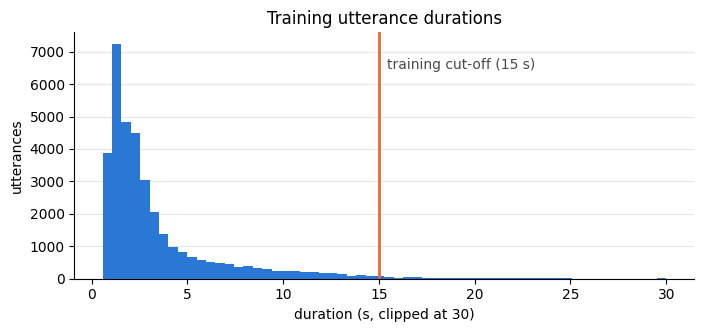

dropped from training: 632 utterances (3.45 h) longer than 15 s


In [10]:
BLUE, ORANGE, GRID, INK = "#2a78d6", "#eb6834", "#e6e6e6", "#4a4a4a"

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(meta[meta.split == "train"].duration.clip(upper=30), bins=60, color=BLUE)
ax.axvline(MAX_TRAIN_SECONDS, color=ORANGE, lw=2)
ax.text(MAX_TRAIN_SECONDS + 0.4, ax.get_ylim()[1] * 0.85, f"training cut-off ({MAX_TRAIN_SECONDS:.0f} s)", color=INK)
ax.set(xlabel="duration (s, clipped at 30)", ylabel="utterances", title="Training utterance durations")
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
wandb.log({"data/train_durations": wandb.Image(fig), "train/global_step": 0})
plt.show()

long = meta[(meta.split == "train") & (meta.duration > MAX_TRAIN_SECONDS)]
print(f"dropped from training: {len(long)} utterances ({long.duration.sum() / 3600:.2f} h) longer than {MAX_TRAIN_SECONDS:.0f} s")

Most utterances are short: isolated words take 1 to 2 s and read sentences 3 to 8 s. A small tail runs past 15 s. These long clips set the padded length of the whole batch, so they are what runs a 16 GB T4 out of memory. Dropping them from training costs very little audio. Validation and test keep every utterance.

In [11]:
train_ds = ds["train"].filter(lambda d: d <= MAX_TRAIN_SECONDS, input_columns="duration")
val_ds = ds["validation"]
test_ds = ds["test"]
if SMOKE_TEST:
    train_ds = train_ds.shuffle(seed=SEED).select(range(16))
    val_ds = val_ds.shuffle(seed=SEED).select(range(8))
    test_ds = test_ds.shuffle(seed=SEED).select(range(8))
val_eval_ds = val_ds.shuffle(seed=SEED).select(range(min(N_EVAL_DURING_TRAINING, len(val_ds))))
print(f"train {len(train_ds)} | validation (scored during training) {len(val_eval_ds)} of {len(val_ds)} | test {len(test_ds)}")
run.config.update({"data": {**run.config["data"], "n_train": len(train_ds), "n_eval_during_training": len(val_eval_ds), "n_test": len(test_ds)}}, allow_val_change=True)

Filter:   0%|          | 0/35359 [00:00<?, ? examples/s]

train 34727 | validation (scored during training) 800 of 5473 | test 5458


## 3. Vocabulary

The pretrained model outputs 392 eSpeak phoneme symbols from many languages. Our labels use about 40 phones (no glottal stop): Tagalog phones plus the English phones that Taglish words bring in. The output layer is replaced with one that has exactly the label phones plus the CTC blank (`<pad>`) and the special tokens. A smaller output layer means the model cannot produce symbols that never occur in the labels.

Labels are a string of phones without spaces. Word boundaries are dropped, as in the repo's other phoneme models, so the model learns phones only. A phone is one character, or two characters joined by a tie bar (`t͡ʃ`, `d͡ʒ`).

In [12]:
PHONE_RE = re.compile(r".͡.|.")


def ipa_to_phones(ipa):
    return PHONE_RE.findall(ipa.replace(" ", ""))


# built from the full training split (also in SMOKE_TEST), so the vocabulary does not depend on the subset
phone_counts = Counter(p for ipa in ds["train"]["ipa"] for p in ipa_to_phones(ipa))
SPECIAL_TOKENS = ["<pad>", "<s>", "</s>", "<unk>"]
phones = sorted(phone_counts, key=lambda p: (-phone_counts[p], p))
vocab = {tok: i for i, tok in enumerate(SPECIAL_TOKENS + phones)}
id2tok = {i: t for t, i in vocab.items()}
PAD_ID, UNK_ID = vocab["<pad>"], vocab["<unk>"]
print(len(phones), "phones:", " ".join(phones))

unseen = {p for split in (val_ds, test_ds) for ipa in split["ipa"] for p in ipa_to_phones(ipa)} - set(vocab)
print("phones in validation/test but not in training:", unseen or "none")

40 phones: a n i ŋ s t o l m p k u ɡ j b d ɾ h e w ɪ ə ɹ ɛ f z ɑ æ ɔ v ɚ ʃ t͡ʃ ʊ d͡ʒ ʌ ɝ θ ð ʒ


phones in validation/test but not in training: none


In [13]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
with open(os.path.join(OUTPUT_DIR, "vocab.json"), "w") as f:
    json.dump(vocab, f, ensure_ascii=False, indent=1)

tokenizer = Wav2Vec2CTCTokenizer(
    os.path.join(OUTPUT_DIR, "vocab.json"),
    pad_token="<pad>",
    unk_token="<unk>",
    bos_token="<s>",
    eos_token="</s>",
    word_delimiter_token="|",  # unused: labels have no spaces
    do_lower_case=False,
)
feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(BASE_MODEL_ID)
processor = Wav2Vec2Processor(feature_extractor=feature_extractor, tokenizer=tokenizer)
processor.save_pretrained(OUTPUT_DIR)


def encode_labels(ipa):
    return [vocab.get(p, UNK_ID) for p in ipa_to_phones(ipa)]


# the saved tokenizer must split labels into the same phones (tie-bar affricates stay one token)
for ipa in train_ds.select(range(min(200, len(train_ds))))["ipa"]:
    assert tokenizer(ipa.replace(" ", "")).input_ids == encode_labels(ipa), ipa
print("tokenizer check passed, e.g.", train_ds[0]["ipa"], "->", encode_labels(train_ds[0]["ipa"]))

preprocessor_config.json:   0%|          | 0.00/212 [00:00<?, ?B/s]

tokenizer check passed, e.g. manuɡaŋ -> [12, 4, 5, 15, 16, 4, 7]


**Initialising the new output layer.** Each output row is a learned vector for one phone. Rather than starting from random values, each new row is **copied from the pretrained row for the same phone**, so fine-tuning starts from what the model already knows. eSpeak writes some phones differently from our labels, so those are mapped by hand:

| our label | pretrained token | note |
|---|---|---|
| `t͡ʃ`, `d͡ʒ` | `tʃ`, `dʒ` | same affricates, without the tie bar |
| `ɝ` | `ɚ` | eSpeak has no stressed r-coloured vowel |

Every label phone gets a pretrained row this way, so none start from scratch (the cell below would list any that do).

In [14]:
base_vocab = json.load(open(snapshot_download(BASE_MODEL_ID, allow_patterns=["vocab.json"]) + "/vocab.json"))
BASE_EQUIVALENT = {"t͡ʃ": "tʃ", "d͡ʒ": "dʒ", "ɝ": "ɚ"}

init_rows = {}
for tok in vocab:
    src = BASE_EQUIVALENT.get(tok, tok)
    init_rows[tok] = (src, base_vocab.get(src))
missing = [t for t, (_, i) in init_rows.items() if i is None]
print("tokens without a pretrained row (random init):", missing or "none")
run.config.update({"model": {**run.config["model"], "vocab_size": len(vocab), "phones": phones}}, allow_val_change=True)
pd.DataFrame(
    [(t, s, i) for t, (s, i) in init_rows.items() if s != t], columns=["new token", "copied from", "base id"]
)

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

vocab.json: 0.00B [00:00, ?B/s]

tokens without a pretrained row (random init): none


,new token,copied from,base id
0,t͡ʃ,tʃ,66
1,d͡ʒ,dʒ,60
2,ɝ,ɚ,43


## 4. Baseline: the pretrained model before fine-tuning

Before training, the pretrained model is scored on the test speakers. Its output is mapped onto our notation first: tie bars are added to affricates, and length marks, stress marks and glottal stops are removed. This baseline shows how much fine-tuning gains.

Two error rates are reported, both summed over the whole set (0% is perfect):

- **Phone error rate (PER)** = (substitutions + deletions + insertions) / number of reference phones. Every error counts as 1, so writing `e` for `i` costs as much as writing `k` for `i`. It can exceed 100% when the model inserts many extra phones.
- **Feature error rate (FER)**: the same alignment, but each edit is weighted by how many **articulatory features** differ (voicing, place, manner, height, rounding, ...), using panphon's weighted feature edit distance, as in the repo's `scripts/eval/metrics.py`. A near miss such as `e` for `i` costs little; `k` for `i` costs a lot. FER is normalised like the repo: divided by twice the sum of panphon's feature weights and by the label length. Before scoring, tie bars are removed (`t͡ʃ` → `tʃ`) and `ɚ`, `ɝ` are written `ə˞`, `ɜ˞`, as in `scripts/eval/evaluate.py`.

FER is the better measure of *how wrong* the model is: two models with the same PER can differ a lot in FER if one makes near misses and the other makes wild ones. Training keeps the checkpoint with the **lowest validation FER**, the repo's usual selection metric.

In [15]:
def edit_ops(ref, hyp):
    # Levenshtein alignment; returns the list of (op, ref_phone, hyp_phone) for errors only
    n, m = len(ref), len(hyp)
    d = np.zeros((n + 1, m + 1), dtype=np.int32)
    d[:, 0], d[0, :] = np.arange(n + 1), np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            d[i, j] = min(d[i - 1, j] + 1, d[i, j - 1] + 1, d[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]))
    ops, i, j = [], n, m
    while i or j:
        if i and j and d[i, j] == d[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]):
            if ref[i - 1] != hyp[j - 1]:
                ops.append(("sub", ref[i - 1], hyp[j - 1]))
            i, j = i - 1, j - 1
        elif i and d[i, j] == d[i - 1, j] + 1:
            ops.append(("del", ref[i - 1], "")); i -= 1
        else:
            ops.append(("ins", "", hyp[j - 1])); j -= 1
    return ops


def corpus_per(refs, hyps):
    errors = sum(len(edit_ops(r, h)) for r, h in zip(refs, hyps))
    return errors / max(1, sum(len(r) for r in refs))


panphon_distance = panphon.distance.Distance()
FER_NORM = 1 / (sum(panphon.FeatureTable().weights) * 2)  # same normalisation as scripts/eval/metrics.py


def to_panphon(phones):
    # same preprocessing as scripts/eval/evaluate.py: no tie bars, r-coloured vowels with ˞
    return "".join(p.replace("͡", "").replace("ɚ", "ə˞").replace("ɝ", "ɜ˞") for p in phones)


def feature_distance(ref, hyp):
    return panphon_distance.weighted_feature_edit_distance(to_panphon(ref), to_panphon(hyp))


def corpus_fer(refs, hyps):
    dist = sum(feature_distance(r, h) for r, h in zip(refs, hyps))
    return FER_NORM * dist / max(1, sum(len(to_panphon(r)) for r in refs))


def ctc_decode(ids, id2tok, blank_id):
    # collapse repeats, then drop blanks and special tokens
    out, prev = [], None
    for i in ids:
        if i != prev and i != blank_id:
            tok = id2tok.get(int(i), "")
            if not (tok.startswith("<") and tok.endswith(">")):
                out.append(tok)
        prev = i
    return out


def load_audio(audio):
    wav, sr = sf.read(io.BytesIO(audio["bytes"]), dtype="float32")
    assert sr == 16000
    return wav


@torch.no_grad()
def transcribe(model, dataset, id2tok, blank_id, max_batch_seconds=120):
    # batches are filled up to max_batch_seconds of padded audio (clips sorted by length), so long clips cannot run out of GPU memory
    model.eval()
    durations = np.asarray(dataset["duration"])
    order = np.argsort(durations)
    batches, current = [], []
    for i in order:
        if current and durations[i] * (len(current) + 1) > max_batch_seconds:
            batches.append(current)
            current = []
        current.append(int(i))
    batches += [current] if current else []

    hyps = [None] * len(dataset)
    for idx in batches:
        rows = dataset.select(idx)
        inputs = feature_extractor(
            [load_audio(a) for a in rows["audio"]], sampling_rate=16000, padding=True, return_attention_mask=True, return_tensors="pt"
        ).to(model.device)
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            logits = model(inputs.input_values, attention_mask=inputs.attention_mask).logits
        for i, ids in zip(idx, logits.argmax(-1).cpu()):
            hyps[i] = ctc_decode(ids.tolist(), id2tok, blank_id)
    return hyps

In [16]:
model = Wav2Vec2ForCTC.from_pretrained(BASE_MODEL_ID).to(DEVICE)

base_id2tok = {i: t for t, i in base_vocab.items()}
TO_OUR_NOTATION = {"tʃ": "t͡ʃ", "dʒ": "d͡ʒ", "g": "ɡ", "ts": "t͡s"}


def base_to_phones(tokens):
    out = []
    for t in tokens:
        t = TO_OUR_NOTATION.get(t, t).replace("ː", "").replace("ˈ", "").replace("ˌ", "").replace("ʔ", "")  # labels have no ʔ
        out += PHONE_RE.findall(t)
    return out


N_BASELINE = len(test_ds) if SMOKE_TEST else min(1000, len(test_ds))
baseline_ds = test_ds.shuffle(seed=SEED).select(range(N_BASELINE))
baseline_refs = [ipa_to_phones(x) for x in baseline_ds["ipa"]]
baseline_hyps = [base_to_phones(h) for h in transcribe(model, baseline_ds, base_id2tok, base_vocab["<pad>"])]
baseline_per = corpus_per(baseline_refs, baseline_hyps)
baseline_fer = corpus_fer(baseline_refs, baseline_hyps)
print(f"baseline on {N_BASELINE} test utterances: PER {baseline_per:.1%}, FER {baseline_fer:.1%}")
run.summary["baseline/test_per"] = baseline_per
run.summary["baseline/test_fer"] = baseline_fer
run.summary["baseline/n_utterances"] = N_BASELINE
wandb.log({
    "baseline/examples": wandb.Table(
        columns=["text", "label", "pretrained model"],
        data=[[t, "".join(r), "".join(h)] for r, h, t in list(zip(baseline_refs, baseline_hyps, baseline_ds["text"]))[:20]],
    ),
    "train/global_step": 0,
})
for r, h, t in list(zip(baseline_refs, baseline_hyps, baseline_ds["text"]))[:5]:
    print(f"\n{t}\n  label: {''.join(r)}\n  model: {''.join(h)}")

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.26G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.26G [00:00<?, ?B/s]

baseline on 1000 test utterances: PER 21.0%, FER 4.6%



Daniel Z. Romualdez Airport
  label: danjelziɾomwaldesɛɹpɔɹt
  model: deɪɲʌlzeɪɹʌmwældɪsɚpɚt

Walang katapusan ang oportunidad kong makakilala ng mga bagong kaibigan at mga bagong kahalakhakan dahil pagngiti ang passport ko sa mga makabuluhang usapan.
  label: walaŋkatapusanaŋopoɾtunidadkoŋmakakilalanaŋmaŋabaɡoŋkaibiɡanatmaŋabaɡoŋkahalakhakandahilpaɡŋitiaŋpæspɔɹtkosamaŋamakabuluhaŋusapan
  model: walaŋxataposanaoportinadadɡoŋmahaxilalenamabaɡuŋxebiɡənatmaabaɡoŋqahalaxhahandahilbaɡɲidiaŋpaspɔtkɔsamaamahɑbolohaŋosapan

Masulat da Maria at Pedro kay Juan.
  label: masulatdamaɾijaatpedɾokajhuwan
  model: masulatdamariatpedroqaɪhoan

13
  label: labintatlo
  model: labiŋtatlo

Discovery Suites
  label: dɪskʌvəɹiswits
  model: dɪskʌvɪɹisit


The pretrained model has never been trained on Tagalog: Common Voice, its fine-tuning data, has no Tagalog. Its errors are a mix of genuine misrecognitions and **notation differences**. For example, it may write a tap as `r` where our labels have `ɾ`. Fine-tuning fixes both kinds of error at once, because it teaches the model our notation as well as Tagalog.

## 5. Training

**Model changes before training**
- The output layer is replaced with the one from section 3.
- The CNN feature encoder (the convolutional layers that read the raw waveform) is **frozen**. It already encodes speech well, and freezing it saves memory and time on a T4. The 24 transformer layers and the output layer are trained.
- CTC loss is averaged per target length (`mean`). `ctc_zero_infinity` stops an occasional impossible alignment (a label longer than the audio allows) from producing an infinite loss.
- SpecAugment masks random stretches of time and frequency during training to reduce overfitting. LayerDrop randomly skips transformer layers for the same reason.

**Collator.** Each batch is decoded from FLAC, normalised by the feature extractor and zero-padded. Padded label positions are set to -100 so the loss ignores them. `group_by_length` puts clips of similar length in the same batch, which cuts the padding a lot.

**Checkpoints and resuming.** A checkpoint is saved every `EVAL_SAVE_STEPS` updates and pushed to `HF_MODEL_ID` (`last-checkpoint` folder). If Colab disconnects, re-run the notebook: the next cell downloads that checkpoint and training continues where it stopped. Free T4 sessions are limited to a few hours, so expect to resume at least once.

In [17]:
old_head = model.lm_head
new_head = torch.nn.Linear(old_head.in_features, len(vocab)).to(old_head.weight.device)
with torch.no_grad():
    for tok, new_id in vocab.items():
        _, base_id = init_rows[tok]
        if base_id is not None:
            new_head.weight[new_id] = old_head.weight[base_id]
            new_head.bias[new_id] = old_head.bias[base_id]
model.lm_head = new_head
model.config.vocab_size = len(vocab)
model.config.pad_token_id = PAD_ID
model.config.bos_token_id = vocab["<s>"]
model.config.eos_token_id = vocab["</s>"]
model.config.ctc_loss_reduction = "mean"
model.config.ctc_zero_infinity = True
model.config.mask_time_prob = MASK_TIME_PROB
model.config.mask_feature_prob = MASK_FEATURE_PROB
model.config.mask_feature_length = 10
model.config.layerdrop = LAYERDROP
model.freeze_feature_encoder()

n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters: {n_train / 1e6:.0f}M of {model.num_parameters() / 1e6:.0f}M")

# sanity check: the new head maps pretrained outputs to the same phones as before
check_hyps = transcribe(model, baseline_ds.select(range(min(3, len(baseline_ds)))), id2tok, PAD_ID)
for h, bh in zip(check_hyps, baseline_hyps):
    print("new head:", "".join(h), "| base:", "".join(bh))

trainable parameters: 311M of 315M
new head: dɛnʌlzeɹʌmwældɪsɚpɚt | base: deɪɲʌlzeɪɹʌmwældɪsɚpɚt
new head: walaŋkataposanaopoɾtinadadɡoŋmahahilalenambaɡuŋhebiɡənatmaabaɡoŋkahalahahandahilbaɡnidiaŋpaspɔtkɔsamaamahɑbolohaŋosapan | base: walaŋxataposanaoportinadadɡoŋmahaxilalenamabaɡuŋxebiɡənatmaabaɡoŋqahalaxhahandahilbaɡɲidiaŋpaspɔtkɔsamaamahɑbolohaŋosapan
new head: masulatdamaɾiatpedoɹahoan | base: masulatdamariatpedroqaɪhoan


In [18]:
class CTCCollator:
    def __call__(self, rows):
        batch = feature_extractor(
            [load_audio(r["audio"]) for r in rows], sampling_rate=16000, padding=True, return_attention_mask=True, return_tensors="pt"
        )
        labels = [encode_labels(r["ipa"]) for r in rows]
        width = max(len(l) for l in labels)
        batch["labels"] = torch.tensor([l + [-100] * (width - len(l)) for l in labels])
        return batch


def preprocess_logits_for_metrics(logits, labels):
    return logits.argmax(-1)


last_eval = {}


def compute_metrics(pred):
    hyps = [ctc_decode(ids, id2tok, PAD_ID) for ids in pred.predictions]
    refs = [[id2tok[i] for i in row if i != -100] for row in pred.label_ids]
    last_eval.update(refs=refs, hyps=hyps)
    return {"per": corpus_per(refs, hyps), "fer": corpus_fer(refs, hyps)}


class WandbExamplesCallback(TrainerCallback):
    # after each evaluation, log a few validation transcriptions so you can watch them improve
    def on_evaluate(self, args, state, control, **kwargs):
        if not last_eval or wandb.run is None:
            return
        rows = [
            ["".join(r), "".join(h), corpus_per([r], [h]), corpus_fer([r], [h])]
            for r, h in list(zip(last_eval["refs"], last_eval["hyps"]))[:15]
        ]
        wandb.log({"eval/examples": wandb.Table(columns=["label", "model", "PER", "FER"], data=rows), "train/global_step": state.global_step})


# Trainer.group_by_length reads lengths from this column (number of audio samples), for training and evaluation
def with_input_length(d):
    return d.add_column("input_length", [round(x * 16000) for x in d["duration"]])


train_ds = with_input_length(train_ds)
val_eval_ds = with_input_length(val_eval_ds)

Flattening the indices:   0%|          | 0/34727 [00:00<?, ? examples/s]

Flattening the indices:   0%|          | 0/800 [00:00<?, ? examples/s]

In [19]:
steps_per_epoch = math.ceil(len(train_ds) / (BATCH_SIZE * GRAD_ACCUM))
print(f"{steps_per_epoch} updates per epoch, {steps_per_epoch * NUM_EPOCHS} in total")

args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LEARNING_RATE,
    warmup_steps=0 if SMOKE_TEST else WARMUP_STEPS,
    num_train_epochs=NUM_EPOCHS,
    max_steps=2 if SMOKE_TEST else -1,
    weight_decay=0.0,
    bf16=DEVICE == "cuda" and torch.cuda.is_bf16_supported(),  # L4/A100: bf16, no loss-scaling skips
    fp16=DEVICE == "cuda" and not torch.cuda.is_bf16_supported(),  # T4: fp16
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},  # the reentrant version gives no gradients with a frozen feature encoder
    group_by_length=True,
    length_column_name="input_length",
    eval_strategy="steps",
    eval_steps=EVAL_SAVE_STEPS,
    save_strategy="steps",
    save_steps=EVAL_SAVE_STEPS,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="fer",  # the checkpoint with the lowest validation FER is kept
    greater_is_better=False,
    logging_steps=1 if SMOKE_TEST else 50,
    dataloader_num_workers=0 if SMOKE_TEST else 2,
    remove_unused_columns=False,
    report_to="wandb",
    run_name=RUN_NAME,
    seed=SEED,
    push_to_hub=PUSH_TO_HUB,
    hub_model_id=HF_MODEL_ID,
    hub_private_repo=True,
    hub_strategy="checkpoint",  # keeps the latest checkpoint in the repo's last-checkpoint/ folder
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_eval_ds,
    data_collator=CTCCollator(),
    processing_class=processor,
    compute_metrics=compute_metrics,
    preprocess_logits_for_metrics=preprocess_logits_for_metrics,
    callbacks=[WandbExamplesCallback()],
)

1086 updates per epoch, 3258 in total


In [20]:
def find_checkpoint():
    # a local checkpoint (same Colab session), else the last one pushed to the hub (after a disconnect)
    local = [d for d in os.listdir(OUTPUT_DIR) if d.startswith("checkpoint-")]
    if local:
        return os.path.join(OUTPUT_DIR, max(local, key=lambda d: int(d.split("-")[1])))
    if PUSH_TO_HUB:
        try:
            path = snapshot_download(HF_MODEL_ID, allow_patterns=["last-checkpoint/*"], local_dir=OUTPUT_DIR)
            if os.path.isfile(os.path.join(path, "last-checkpoint", "trainer_state.json")):
                return os.path.join(path, "last-checkpoint")
        except Exception as e:
            print("no checkpoint on the hub yet:", type(e).__name__)
    return None


checkpoint = find_checkpoint()
print("resuming from", checkpoint) if checkpoint else print("starting from the pretrained model")
train_result = trainer.train(resume_from_checkpoint=checkpoint)
print(train_result.metrics)

Fetching 0 files: 0it [00:00, ?it/s]

starting from the pretrained model


Step,Training Loss,Validation Loss,Per,Fer
500,1.290100,0.528305,0.146001,0.033188
1000,0.914900,0.393354,0.120892,0.026645
1500,0.823300,0.338695,0.110399,0.022095
2000,0.965200,0.569518,0.209529,0.071059
2500,1.173500,0.661724,0.188993,0.057498
3000,1.098900,0.535497,0.157759,0.043287


{'train_runtime': 3181.9097, 'train_samples_per_second': 32.742, 'train_steps_per_second': 1.024, 'total_flos': 1.0157334574286207e+19, 'train_loss': 1.166008689346454, 'epoch': 3.0}


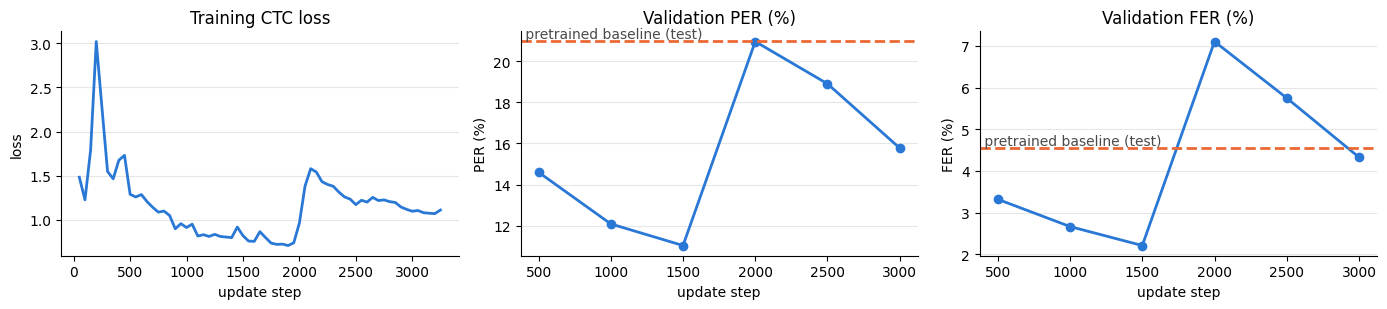

best checkpoint: /content/xlsr-53-espeak-pld-fil/checkpoint-1500 | best validation FER: 0.022094767988108426


In [21]:
log = pd.DataFrame(trainer.state.log_history)
loss = log.dropna(subset=["loss"]) if "loss" in log else log.iloc[:0]
evals = log.dropna(subset=["eval_per"]) if "eval_per" in log else log.iloc[:0]

if evals.empty:
    print("no evaluation logged yet")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
axes[0].plot(loss.step, loss.loss, color=BLUE, lw=2)
axes[0].set(title="Training CTC loss", xlabel="update step", ylabel="loss")
for ax, col, base, name in [(axes[1], "eval_per", baseline_per, "PER"), (axes[2], "eval_fer", baseline_fer, "FER")]:
    if col in evals:
        ax.plot(evals.step, evals[col] * 100, color=BLUE, lw=2, marker="o", ms=6)
    ax.axhline(base * 100, color=ORANGE, lw=2, ls="--")
    ax.text(ax.get_xlim()[0], base * 100, " pretrained baseline (test)", va="bottom", color=INK)
    ax.set(title=f"Validation {name} (%)", xlabel="update step", ylabel=f"{name} (%)")
for ax in axes:
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
print("best checkpoint:", trainer.state.best_model_checkpoint, "| best validation FER:", trainer.state.best_metric)
run.summary["best_checkpoint"] = trainer.state.best_model_checkpoint
run.summary["eval/best_fer"] = trainer.state.best_metric

**Reading the curves.** The loss should fall quickly in the first few hundred steps, because the output layer only has to learn our notation, and then slowly after that. Validation PER and FER should follow it. FER usually sits well below PER, because many remaining errors are near misses between similar sounds. If the validation rates stop improving while the loss keeps falling, the model is starting to memorise the training speakers. The best checkpoint (lowest validation FER) is loaded at the end either way.

## 6. Evaluation on the held-out test speakers

The best checkpoint now transcribes the **whole test set**: speakers it has never heard. PER and FER are reported overall, by prompt category, for prompts the model never heard in training, by label source, and by gender and age band. The baseline is shown for the same utterances.

In [22]:
model = trainer.model
torch.cuda.empty_cache()
test_refs = [ipa_to_phones(x) for x in test_ds["ipa"]]
test_hyps = transcribe(model, test_ds, id2tok, PAD_ID)
test_meta = test_ds.remove_columns("audio").to_pandas()
test_meta["ref"], test_meta["hyp"] = test_refs, test_hyps
test_meta["errors"] = [len(edit_ops(r, h)) for r, h in zip(test_refs, test_hyps)]
test_meta["n_ref"] = [len(r) for r in test_refs]
test_meta["fdist"] = [feature_distance(r, h) for r, h in zip(test_refs, test_hyps)]
test_meta["n_ref_chars"] = [len(to_panphon(r)) for r in test_refs]

base = pd.DataFrame({
    "id": baseline_ds["id"],
    "base_errors": [len(edit_ops(r, h)) for r, h in zip(baseline_refs, baseline_hyps)],
    "base_fdist": [feature_distance(r, h) for r, h in zip(baseline_refs, baseline_hyps)],
})
test_meta = test_meta.merge(base, on="id", how="left")
test_meta["age_band"] = pd.cut(test_meta.speaker_age, [0, 18, 20, 200], labels=["16-18", "19-20", "21+"]).astype(str)
test_meta["prompt"] = np.where(test_meta.text_in_train, "prompt also in training", "prompt never in training")

per_fine = test_meta.errors.sum() / test_meta.n_ref.sum()
fer_fine = FER_NORM * test_meta.fdist.sum() / test_meta.n_ref_chars.sum()
on_base = test_meta.dropna(subset=["base_errors"])
fine_on_base = (on_base.errors.sum() / on_base.n_ref.sum(), FER_NORM * on_base.fdist.sum() / on_base.n_ref_chars.sum())
print(f"test, fine-tuned: PER {per_fine:.1%}, FER {fer_fine:.1%} ({len(test_meta)} utterances, {test_meta.speaker_id.nunique()} speakers)")
print(f"on the {len(on_base)} baseline utterances: PER {baseline_per:.1%} -> {fine_on_base[0]:.1%}, FER {baseline_fer:.1%} -> {fine_on_base[1]:.1%}")
run.summary["test/per"] = per_fine
run.summary["test/fer"] = fer_fine
run.summary["test/per_on_baseline_subset"] = fine_on_base[0]
run.summary["test/fer_on_baseline_subset"] = fine_on_base[1]
run.summary["test/n_utterances"] = len(test_meta)
run.summary["test/n_speakers"] = test_meta.speaker_id.nunique()

test, fine-tuned: PER 8.3%, FER 2.2% (5458 utterances, 15 speakers)
on the 1000 baseline utterances: PER 21.0% -> 8.6%, FER 4.6% -> 2.2%


In [23]:
RATE_FORMAT = {c: "{:.1%}" for c in ["PER fine-tuned", "PER pretrained", "FER fine-tuned", "FER pretrained"]}


def per_by(col):
    has_base = test_meta.base_errors.notna()
    t = test_meta.assign(n_ref_base=test_meta.n_ref.where(has_base, 0), n_ref_chars_base=test_meta.n_ref_chars.where(has_base, 0))
    g = t.groupby(col)
    out = pd.DataFrame({
        "utterances": g.size(),
        "PER fine-tuned": g.errors.sum() / g.n_ref.sum(),
        "PER pretrained": g.base_errors.sum() / g.n_ref_base.sum(),
        "FER fine-tuned": FER_NORM * g.fdist.sum() / g.n_ref_chars.sum(),
        "FER pretrained": FER_NORM * g.base_fdist.sum() / g.n_ref_chars_base.sum(),
    })
    return out.sort_values("FER fine-tuned")


by_category = per_by("category")
for cat, row in by_category.iterrows():
    run.summary[f"test/category_per/{cat}"] = row["PER fine-tuned"]
    run.summary[f"test/category_fer/{cat}"] = row["FER fine-tuned"]
category_table = wandb.Table(dataframe=by_category.reset_index().rename(columns={"index": "category"}))
wandb.log({
    "test/per_by_category": category_table,
    "test/per_by_category_chart": wandb.plot.bar(category_table, "category", "PER fine-tuned", title="Test PER by prompt category"),
    "test/fer_by_category_chart": wandb.plot.bar(category_table, "category", "FER fine-tuned", title="Test FER by prompt category"),
})
by_category.style.format(RATE_FORMAT)

,utterances,PER fine-tuned,PER pretrained,FER fine-tuned,FER pretrained
category,,,,,
digits,110,4.9%,12.9%,1.3%,1.7%
dialect (Shib),289,8.5%,26.5%,2.1%,5.7%
read sentences,2703,7.9%,20.5%,2.2%,4.6%
isolated words,2236,11.2%,22.7%,2.4%,4.0%
named entities,120,17.4%,33.3%,3.5%,5.9%


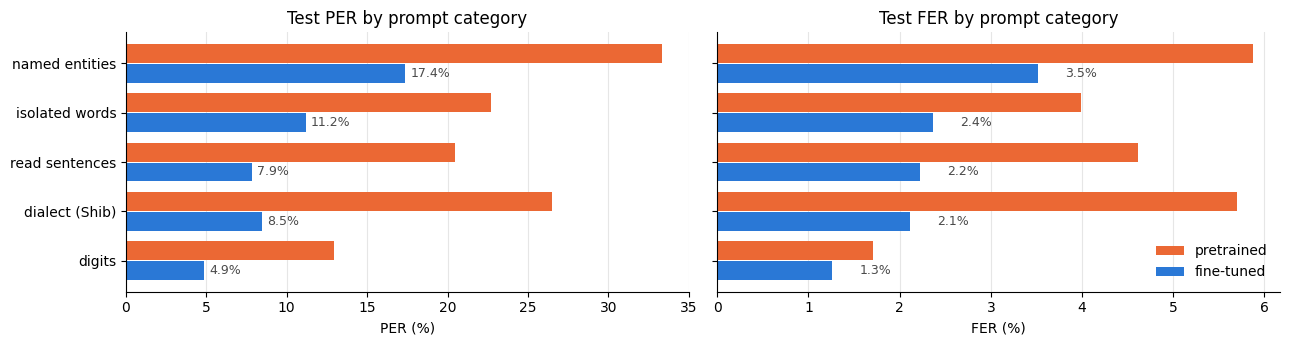

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 0.8 + 0.55 * len(by_category)), sharey=True)
y = np.arange(len(by_category))
for ax, name in zip(axes, ["PER", "FER"]):
    ax.barh(y + 0.2, by_category[f"{name} pretrained"] * 100, height=0.38, color=ORANGE, label="pretrained")
    ax.barh(y - 0.2, by_category[f"{name} fine-tuned"] * 100, height=0.38, color=BLUE, label="fine-tuned")
    for yi, v in zip(y, by_category[f"{name} fine-tuned"] * 100):
        ax.text(v + 0.3, yi - 0.2, f"{v:.1f}%", va="center", color=INK, fontsize=9)
    ax.set(xlabel=f"{name} (%)", title=f"Test {name} by prompt category")
    ax.grid(axis="x", color=GRID)
    ax.set_axisbelow(True)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
axes[0].set_yticks(y, by_category.index)
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout()
wandb.log({"test/per_by_category_vs_pretrained": wandb.Image(fig)})
plt.show()

In [25]:
# unseen prompts, label source (confirmed = every word from Wiktionary/WikiPron), gender and age band
breakdowns = {col: per_by(col) for col in ["prompt", "label_source", "speaker_gender", "age_band"]}
for col, table in breakdowns.items():
    for value, row in table.iterrows():
        run.summary[f"test/{col}/{value}/fer"] = row["FER fine-tuned"]
    wandb.log({f"test/by_{col}": wandb.Table(dataframe=table.reset_index())})
for col, table in breakdowns.items():
    display(table.style.format(RATE_FORMAT).set_caption(col))

,utterances,PER fine-tuned,PER pretrained,FER fine-tuned,FER pretrained
prompt,,,,,
prompt also in training,4429,6.9%,19.5%,1.9%,4.2%
prompt never in training,1029,11.9%,24.8%,3.1%,5.4%


,utterances,PER fine-tuned,PER pretrained,FER fine-tuned,FER pretrained
label_source,,,,,
rule-based,2347,8.0%,20.6%,2.2%,4.6%
confirmed,3111,9.2%,22.0%,2.3%,4.5%


,utterances,PER fine-tuned,PER pretrained,FER fine-tuned,FER pretrained
speaker_gender,,,,,
male,2694,7.2%,18.6%,2.0%,4.0%
female,2764,9.2%,22.5%,2.4%,4.9%


,utterances,PER fine-tuned,PER pretrained,FER fine-tuned,FER pretrained
age_band,,,,,
19-20,1478,7.9%,21.4%,2.1%,4.8%
21+,2323,7.9%,21.0%,2.2%,4.6%
16-18,1657,9.1%,20.6%,2.4%,4.4%


**How to read the breakdowns**
- **By category.** Isolated words are short, so a single wrong phone is a large share of the word. Read sentences give the model more context. A high error rate on *digits* or *named entities* usually points back to the labels: number readings and foreign names are where the G2P had to guess most.
- **Prompts never in training.** The most honest number: new speakers *and* new prompts. If it is much worse than the score on prompts that were also in training, part of the overall score comes from having heard those prompts before.
- **By label source.** Utterances whose words are all Wiktionary entries or forms derived from them (`confirmed`) have the most reliable labels. If utterances with Epitran or rule-based words score much worse, some of that gap is **label noise**, not model error. The model may be saying what the speaker said while the rule-based label is wrong.
- **By gender and age band.** The split is balanced on both, so a large gap here would point to the model, not to the data.

In [26]:
ops = Counter(op for r, h in zip(test_refs, test_hyps) for op in edit_ops(r, h))
confusions = pd.DataFrame(
    [(kind, ref or "∅", hyp or "∅", n) for (kind, ref, hyp), n in ops.most_common(20)],
    columns=["error", "label phone", "model phone", "count"],
)
wandb.log({"test/top_confusions": wandb.Table(dataframe=confusions)})
confusions

,error,label phone,model phone,count
0,sub,u,o,880
1,del,n,∅,604
2,del,ŋ,∅,553
3,del,a,∅,512
4,sub,ɛ,e,474
5,del,i,∅,424
6,sub,ɪ,i,373
7,sub,i,e,364
8,sub,ɹ,ɾ,345
9,sub,i,j,328


**Common confusions.** With glottal stops gone from the labels, expect vowel pairs that Tagalog speakers merge or keep only weakly apart (`e`/`i`, `o`/`u`), English vowels in Taglish words (`ɪ`/`i`, `ə`/`a`), tap versus trill, and phones dropped in fast read speech.

In [27]:
worst = test_meta.assign(
    per=test_meta.errors / test_meta.n_ref.clip(lower=1), fer=FER_NORM * test_meta.fdist / test_meta.n_ref_chars.clip(lower=1)
).sort_values("fer", ascending=False)
pd.set_option("display.max_colwidth", 80)
audio_by_id = {r["id"]: r["audio"] for r in test_ds.select_columns(["id", "audio"]) if r["id"] in set(worst.head(10).id)}
wandb.log({
    "test/worst_examples": wandb.Table(
        columns=["id", "category", "text", "audio", "label", "model", "PER", "FER"],
        data=[
            [r.id, r.category, r.text, wandb.Audio(load_audio(audio_by_id[r.id]), sample_rate=16000), "".join(r.ref), "".join(r.hyp), r.per, r.fer]
            for r in worst.head(10).itertuples()
        ],
    )
})
worst.head(10)[["id", "category", "text", "per", "fer"]].assign(
    label=worst.head(10).ref.map("".join), model=worst.head(10).hyp.map("".join)
)

,id,category,text,per,fer,label,model
5438,0156.120228.081412.0246,read sentences,May fourth.,1.142857,0.412562,majfɔɹθ,majoakwatɾo
5426,0156.120228.081412.0233,read sentences,I forgot tax free yesterday.,1.318182,0.409295,ajfɚɡɑttæksfɹijɛstɹdeɪ,nalimutankoŋseliŋapaleseesemkahapon
4748,0143.120201.050119.0189,read sentences,That's terrible.,1.600000,0.380094,ðætstɛɚbəl,aŋsaklapnamanjan
5445,0156.120228.081412.0253,read sentences,I have to get to my sister's wedding by this flight.,1.282051,0.375000,ajhævtoʊɡɛttoʊmaɪsɪstɚzwɛdɪŋbaɪðəsflaɪt,kajlaŋankoŋmakaabotsakasalaŋkapatidkokajasumakajnaakoaɡadito
5441,0156.120228.081412.0249,read sentences,Which ferry should I take?,1.187500,0.343813,wɪt͡ʃfɛɹiʃədajteɪk,anoŋd͡ʒipaŋdapatkoŋsakjan
5436,0156.120228.081412.0244,read sentences,That car has good handling.,1.157895,0.304900,ðætkɑɹhæsɡʊdhændlɪŋ,maɡandaaŋɡawasakot͡ʃeŋijan
5457,0156.120228.081412.0265,read sentences,Stay loose.,1.000000,0.301724,steɪlus,kalmalaŋ
4761,0143.120201.050119.0207,read sentences,Will your order include drinks?,0.954545,0.273238,wɪljɔɹoɹdɚɪnkluddɹɪŋks,majinominbajonnakasama
4753,0143.120201.050119.0194,read sentences,I wrote the tip here.,1.000000,0.255747,ajɹoʊtðitiphiɚ,sinulatkojandito
4755,0143.120201.050119.0196,read sentences,Do you have a Dunhill's?,0.937500,0.252155,doʊihæveɪdunhils,majwinstankajo


## 7. Saving the model

The best model and its processor (feature extractor + tokenizer) are pushed to `HF_MODEL_ID`. The test results are saved in the model card. To use the model elsewhere:

```python
from transformers import Wav2Vec2ForCTC, Wav2Vec2Processor
processor = Wav2Vec2Processor.from_pretrained(HF_MODEL_ID)
model = Wav2Vec2ForCTC.from_pretrained(HF_MODEL_ID)
inputs = processor(audio_16khz, sampling_rate=16000, return_tensors="pt")
ipa = processor.batch_decode(model(**inputs).logits.argmax(-1))[0]
```

In [28]:
trainer.save_model(OUTPUT_DIR)
processor.save_pretrained(OUTPUT_DIR)
results = {
    "test_per": float(per_fine),
    "test_fer": float(fer_fine),
    "baseline_test_per": float(baseline_per),
    "baseline_test_fer": float(baseline_fer),
    "test_per_by_category": {k: float(v) for k, v in by_category["PER fine-tuned"].items()},
    "test_fer_by_category": {k: float(v) for k, v in by_category["FER fine-tuned"].items()},
    "test_fer_by": {col: {str(k): float(v) for k, v in t["FER fine-tuned"].items()} for col, t in breakdowns.items()},
}
json.dump(results, open(os.path.join(OUTPUT_DIR, "test_results.json"), "w"), indent=1)
print(json.dumps(results, indent=1))

if PUSH_TO_HUB:
    trainer.push_to_hub(commit_message=f"final model, test PER {per_fine:.1%}, FER {fer_fine:.1%}")
    print("pushed to https://huggingface.co/" + HF_MODEL_ID)
    run.summary["hub_model"] = "https://huggingface.co/" + HF_MODEL_ID

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...pld-fil/training_args.bin: 100%|##########| 5.97kB / 5.97kB            

  ...pld-fil/model.safetensors:   4%|3         | 48.0MB / 1.26GB            

{
 "test_per": 0.08304619928275087,
 "test_fer": 0.022363915665805752,
 "baseline_test_per": 0.20962503690581635,
 "baseline_test_fer": 0.04560411988625707,
 "test_per_by_category": {
  "digits": 0.04866180048661801,
  "dialect (Shib)": 0.08453179929689997,
  "read sentences": 0.0786397586253482,
  "isolated words": 0.11191054934370442,
  "named entities": 0.17384952520087654
 },
 "test_fer_by_category": {
  "digits": 0.012577956763710603,
  "dialect (Shib)": 0.02111830070712862,
  "read sentences": 0.02220712618163726,
  "isolated words": 0.023636587722258618,
  "named entities": 0.03513686964678005
 },
 "test_fer_by": {
  "prompt": {
   "prompt also in training": 0.0191316075766382,
   "prompt never in training": 0.030793418389911148
  },
  "label_source": {
   "rule-based": 0.02231072717691482,
   "confirmed": 0.022523488008225817
  },
  "speaker_gender": {
   "male": 0.019964089430662076,
   "female": 0.024216354044182136
  },
  "age_band": {
   "19-20": 0.02114020851943022,
   "21

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...pld-fil/training_args.bin: 100%|##########| 5.97kB / 5.97kB            

  ...pld-fil/model.safetensors:   4%|3         | 48.0MB / 1.26GB            

pushed to https://huggingface.co/jomszxcvb/xlsr-53-espeak-pld-fil-03


In [29]:
# the saved processor decodes the same way as the notebook's own CTC decoding
reloaded = Wav2Vec2Processor.from_pretrained(OUTPUT_DIR)
sample = test_ds[0]
inputs = reloaded(load_audio(sample["audio"]), sampling_rate=16000, return_tensors="pt").to(model.device)
with torch.no_grad():
    ids = model(**inputs).logits.argmax(-1)
print("label:", sample["ipa"].replace(" ", ""))
print("model:", reloaded.batch_decode(ids)[0])

label: bajaw
model: bajaw


In [30]:
print("W&B run:", run.url)
wandb.finish()

W&B run: https://wandb.ai/tiniglabs/pld-fil-xlsr-espeak/runs/xlsr-53-espeak-pld-fil-03


wandb: updating run metadata


wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml


wandb: uploading wandb-summary.json; uploading config.yaml


wandb: 
wandb: Run history:
wandb:                eval/fer ▃▂▁█▆▄
wandb:               eval/loss ▅▂▁▆█▅
wandb:                eval/per ▄▂▁█▇▄
wandb:            eval/runtime ▅█▇▁█▆
wandb: eval/samples_per_second ▄▁▂█▁▃
wandb:   eval/steps_per_second ▄▁▂█▁▃
wandb:             train/epoch ▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇███
wandb:       train/global_step ▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇██████
wandb:         train/grad_norm ▃▃▂▄▃▄▂▂▂▂█▂▅▂▂▁▁▁▂▁▂▁▁▁▁▄▂▅▆▆▄▃▄▂▆▄▅▇▅▅
wandb:     train/learning_rate ▂▃▄▅▆███▇▇▇▇▇▆▆▆▆▆▅▅▅▅▅▄▄▄▄▄▄▃▃▃▃▃▂▂▂▂▂▁
wandb:                      +1 ...
wandb: 
wandb: Run summary:
wandb:   baseline/n_utterances 1000
wandb:       baseline/test_fer 0.0456
wandb:       baseline/test_per 0.20963
wandb:         best_checkpoint /content/xlsr-53-esp...
wandb:           eval/best_fer 0.02209
wandb:                eval/fer 0.04329
wandb:               eval/loss 0.5355
wandb:                eval/per 0.15776
wandb:            eval/runtime 18.1221
wandb: eval/samples_per_second 

wandb: 🚀 View run xlsr-53-espeak-pld-fil-03 at: https://wandb.ai/tiniglabs/pld-fil-xlsr-espeak/runs/xlsr-53-espeak-pld-fil-03
wandb: ⭐️ View project at: https://wandb.ai/tiniglabs/pld-fil-xlsr-espeak
wandb: Synced 5 W&B file(s), 18 media file(s), 42 artifact file(s) and 0 other file(s)


wandb: Find logs at: ./wandb/run-20261030_161746-xlsr-53-espeak-pld-fil-03/logs
